# DREAM4 Time Series Visualization

This notebook visualizes the time-series gene expression data from the DREAM4 In Silico Network Challenge. The datasets contain concatenated trajectories (each 21 time points long) representing the system's response to different perturbations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Use a nice plotting style
plt.style.use('seaborn-v0_8-darkgrid')

In [2]:
# Load the first size-100 time series dataset
filepath = 'data/DREAM4/timeseries_data/insilico_size100_1_timeseries.csv'
df = pd.read_csv(filepath)

print(f"Data shape: {df.shape}")
print("The rows represent time steps (10 perturbations * 21 timepoints = 210 rows).")
print("The columns represent the 100 genes.")
df.head()

Data shape: (210, 100)
The rows represent time steps (10 perturbations * 21 timepoints = 210 rows).
The columns represent the 100 genes.


,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.694559,-0.629500,0.592849,0.353537,-0.008420,-0.092404,1.681469,0.094833,-0.351591,0.606565,...,0.444244,0.378500,0.656748,-0.118333,0.352080,0.055233,-1.302597,0.511374,0.060108,-0.228745
1,-0.606622,-0.974850,-0.670981,-2.058043,-1.089731,0.492786,0.515441,-0.458311,-0.402283,-0.709033,...,0.482477,0.683271,0.064360,0.939824,1.642890,0.880922,-0.497905,-0.107214,0.186743,0.253185
2,-0.392682,-0.440577,-1.514207,-2.098805,-0.698442,-0.585746,-0.482182,-1.062695,-0.240067,-0.998310,...,0.251231,0.524472,-0.001006,0.715885,0.417078,0.524468,0.480232,0.417253,1.061916,0.804151
3,-0.613100,-0.116151,-1.095484,-2.509490,0.050972,0.950830,0.857334,-0.274919,0.516009,-1.346738,...,-0.462181,-0.225054,0.071958,0.359400,1.187904,0.175277,-1.251898,0.839328,1.314319,-0.403054
4,0.479415,-0.364017,-1.681098,-1.920620,0.769521,-0.268940,-0.364706,0.643286,0.229294,-1.669797,...,-0.081178,0.849352,0.579324,0.814696,1.965713,-1.205093,1.373783,0.023181,0.305523,-0.538643


## 1. Line Plot of a Single Trajectory
Let's look at the first perturbation (the first 21 time points) and plot the trajectories of the first 10 genes so it's not too cluttered.

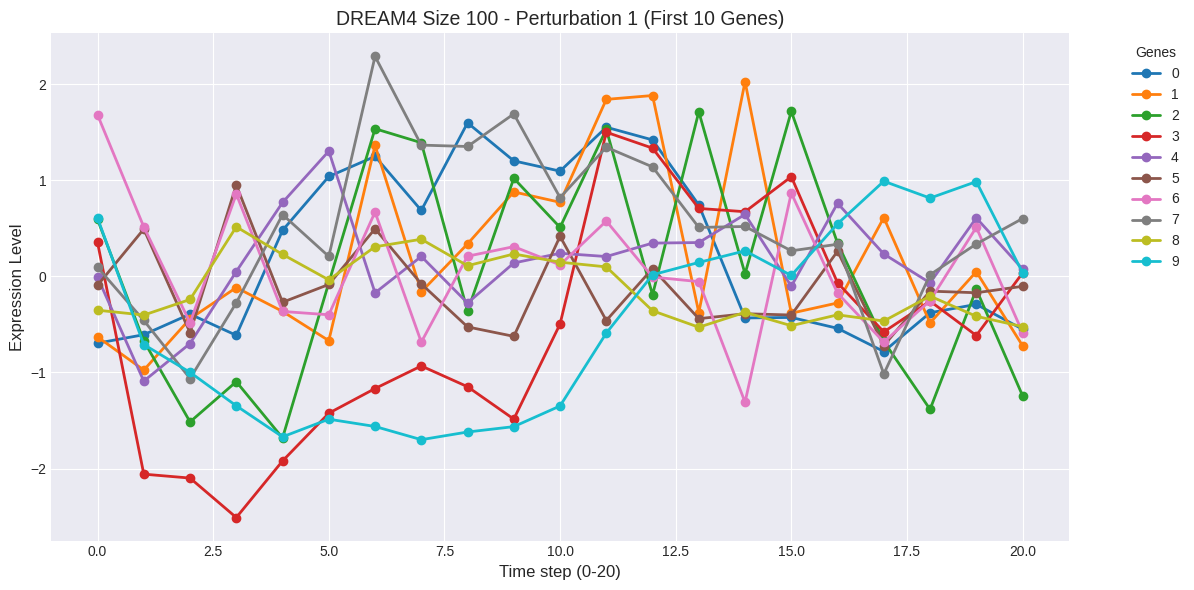

In [3]:
# Extract the first trajectory (rows 0 to 20)
traj_1 = df.iloc[:21, :]

plt.figure(figsize=(12, 6))
traj_1.iloc[:, :10].plot(ax=plt.gca(), marker='o', linewidth=2)
plt.title('DREAM4 Size 100 - Perturbation 1 (First 10 Genes)', fontsize=14)
plt.xlabel('Time step (0-20)', fontsize=12)
plt.ylabel('Expression Level', fontsize=12)
plt.legend(title='Genes', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 2. Heatmap of System-Wide Expression
To see the global response of all 100 genes across the first perturbation, a heatmap is useful.

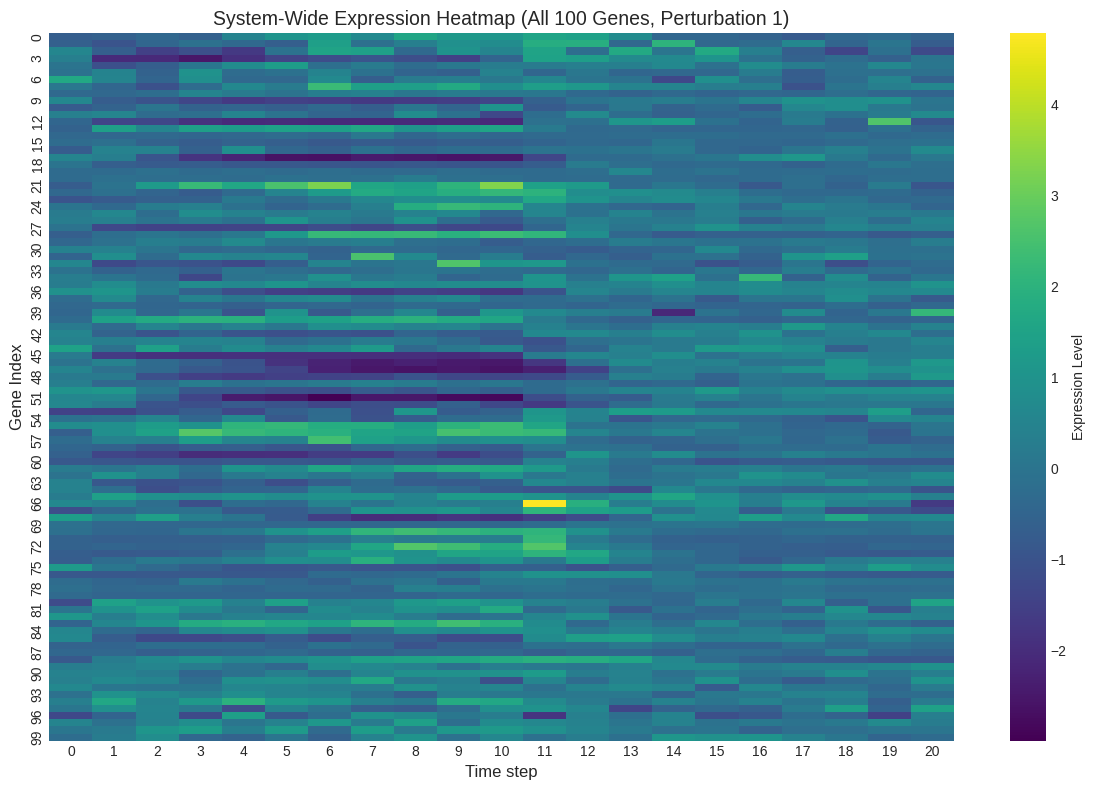

In [4]:
plt.figure(figsize=(12, 8))
sns.heatmap(traj_1.T, cmap='viridis', cbar_kws={'label': 'Expression Level'})
plt.title('System-Wide Expression Heatmap (All 100 Genes, Perturbation 1)', fontsize=14)
plt.xlabel('Time step', fontsize=12)
plt.ylabel('Gene Index', fontsize=12)
plt.tight_layout()
plt.show()

## 3. Comparing Multiple Trajectories
Let's look at how a specific gene (e.g., Gene '0') behaves across all 10 different perturbations.

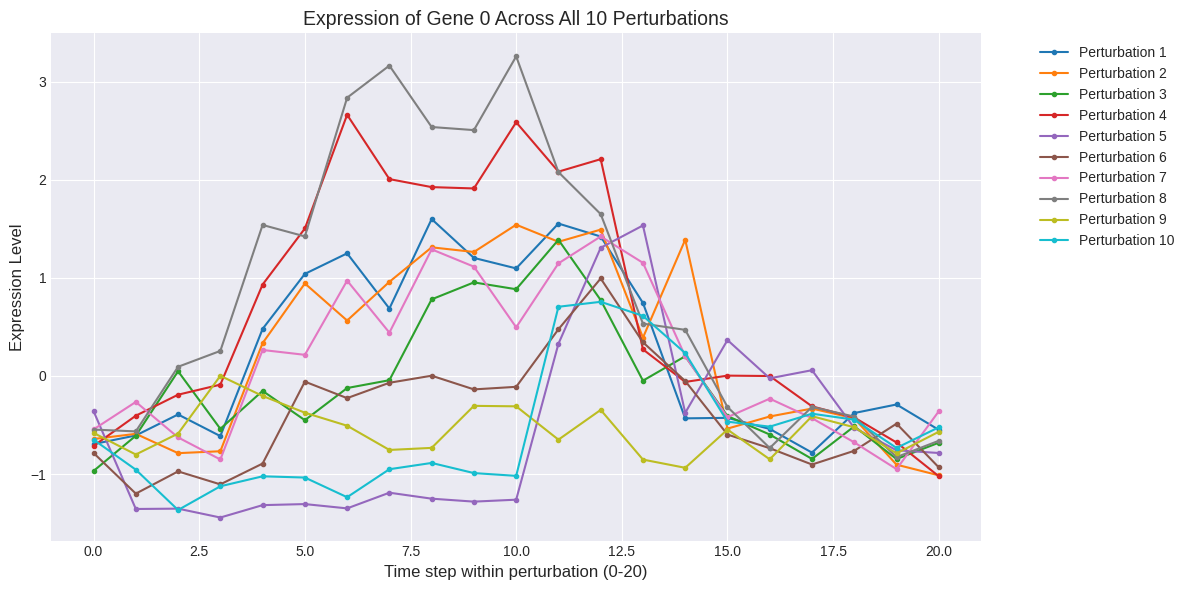

In [5]:
gene_idx = '0' # Column name for the first gene
n_timepoints = 21
n_perturbations = len(df) // n_timepoints

plt.figure(figsize=(12, 6))
for i in range(n_perturbations):
    start_row = i * n_timepoints
    end_row = start_row + n_timepoints
    plt.plot(df.iloc[start_row:end_row][gene_idx].values, marker='.', label=f'Perturbation {i+1}')

plt.title(f'Expression of Gene {gene_idx} Across All 10 Perturbations', fontsize=14)
plt.xlabel('Time step within perturbation (0-20)', fontsize=12)
plt.ylabel('Expression Level', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()